<a href="https://colab.research.google.com/github/dimasrhesky270206/Pcvk_SEMESTER-5/blob/main/Pertemuan_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


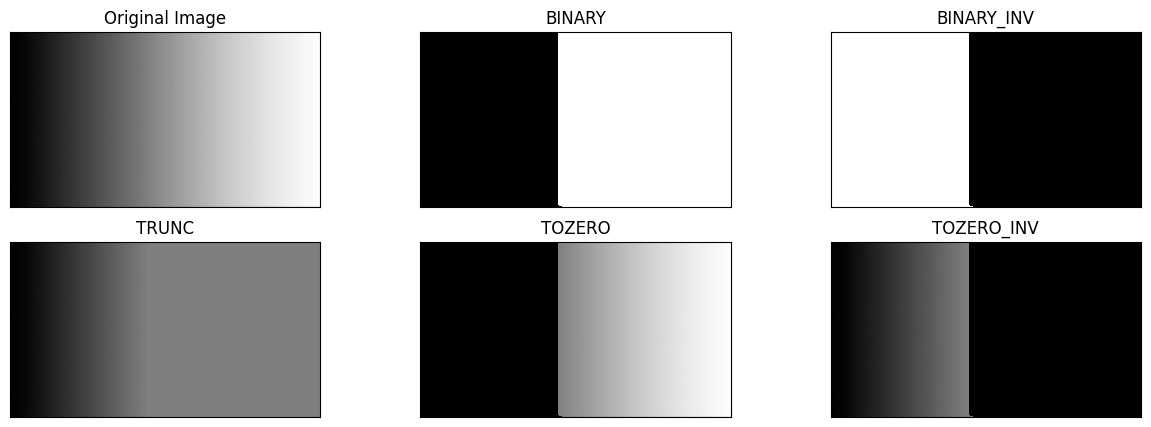

In [4]:
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import matplotlib.pyplot as plt

# Membaca gambar
filename = '/content/drive/MyDrive/pcvk/gradient.png'
img = cv.imread(filename)

# Nilai threshold yang ditentukan
thresh = 127
maxval = 255

# 1. Threshold Binary
# Jika pixel > 127, maka bernilai 255 (putih)
# Selain itu bernilai 0 (hitam)
ret, thresh1 = cv.threshold(
    img, thresh, maxval, cv.THRESH_BINARY
)

# 2. Threshold Binary Inverse
# Jika pixel > 127, maka bernilai 0
# Selain itu bernilai 255
ret, thresh2 = cv.threshold(
    img, thresh, maxval, cv.THRESH_BINARY_INV
)

# 3. Threshold Truncate
# Jika pixel > 127, maka bernilai 127
# Selain itu nilainya tetap
ret, thresh3 = cv.threshold(
    img, thresh, maxval, cv.THRESH_TRUNC
)

# 4. Threshold Tozero
# Jika pixel > 127, maka nilainya tetap
# Selain itu bernilai 0
ret, thresh4 = cv.threshold(
    img, thresh, maxval, cv.THRESH_TOZERO
)

# 5. Threshold Tozero Inverse
# Jika pixel > 127, maka bernilai 0
# Selain itu nilainya tetap
ret, thresh5 = cv.threshold(
    img, thresh, maxval, cv.THRESH_TOZERO_INV
)

# Judul dan hasil gambar
titles = [
    'Original Image',
    'BINARY',
    'BINARY_INV',
    'TRUNC',
    'TOZERO',
    'TOZERO_INV'
]

images = [
    img,
    thresh1,
    thresh2,
    thresh3,
    thresh4,
    thresh5
]

# Menampilkan hasil
plt.figure(figsize=(15, 5))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(
        images[i],
        'gray',
        interpolation='nearest'
    )
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

In [ ]:
filename = '/content/drive/MyDrive/pcvk/sudoku.png'

# Membaca citra dan melakukan median blur
citra = cv.medianBlur(cv.imread(filename), 5)

# Mengubah citra menjadi grayscale
gray = cv.cvtColor(citra, cv.COLOR_BGR2GRAY)

# Nilai threshold global
thresh = 127

# Global Thresholding
ret, th1 = cv.threshold(
    gray,
    thresh,
    255,
    cv.THRESH_BINARY
)

# Adaptive Mean Thresholding
th2 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_MEAN_C,
    cv.THRESH_BINARY,
    11,
    2
)

# Adaptive Gaussian Thresholding
th3 = cv.adaptiveThreshold(
    gray,
    255,
    cv.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv.THRESH_BINARY,
    11,
    2
)

# Judul setiap hasil
titles = [
    'Citra Asli',
    'Global Thresholding (v = 127)',
    'Adaptive Mean Thresholding',
    'Adaptive Gaussian Thresholding'
]

# Menyimpan hasil citra
citra2 = [
    gray,
    th1,
    th2,
    th3
]

# Menampilkan hasil
plt.figure(figsize=(10, 10))

for i in range(len(citra2)):
    plt.subplot(2, 2, i + 1)
    plt.imshow(citra2[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

LIBRARY OPENCV


In [ ]:
filename = '/content/drive/MyDrive/pcvk/lena_lc.jpg'

# Membaca citra grayscale
img = cv.imread(filename, 0)

# Gaussian Blur
blur = cv.GaussianBlur(img, (5, 5), 0)

# Global Thresholding
thresh = 127
ret, th1 = cv.threshold(
    blur,
    thresh,
    255,
    cv.THRESH_BINARY
)

# Otsu's Thresholding menggunakan library
ret2, th2 = cv.threshold(
    blur,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Judul hasil Otsu
x = "Otsu's Thresholding dgn library (v = " + str(ret2) + ")"

titles = [
    'Citra Asli',
    'Global Thresholding (v = 127)',
    x
]

citra3 = [
    blur,
    th1,
    th2
]

# Menampilkan histogram dan hasil thresholding
plt.figure(figsize=(10, 10))

# Histogram citra asli
plt.subplot(2, 2, 1)
plt.hist(blur.ravel(), 256, [50, 200])

# Garis vertikal merah menunjukkan threshold global 127
plt.vlines(
    ret,
    0,
    40000,
    colors='red'
)

# Garis vertikal hitam menunjukkan threshold Otsu
plt.vlines(
    ret2,
    0,
    40000,
    colors='black'
)

plt.title('Histogram Citra Asli')

# Menampilkan hasil citra
for i in range(len(citra3)):
    plt.subplot(2, 2, i + 2)
    plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.show()

In [ ]:
filename = '/content/drive/MyDrive/pcvk/noisy.png'

# Membaca citra grayscale
img = cv.imread(filename, 0)

# Global Thresholding
ret1, th1 = cv.threshold(
    img,
    127,
    255,
    cv.THRESH_BINARY
)

# Otsu's Thresholding
ret2, th2 = cv.threshold(
    img,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Otsu's Thresholding setelah dilakukan Gaussian Filtering
blur = cv.GaussianBlur(img, (5, 5), 0)

ret3, th3 = cv.threshold(
    blur,
    0,
    255,
    cv.THRESH_BINARY + cv.THRESH_OTSU
)

# Plotting semua image
images = [
    img, 0, th1,
    img, 0, th2,
    blur, 0, th3
]

titles = [
    'Image Noisy Asli',
    'Histogram',
    'Global Thresholding (v=127)',

    'Image Noisy Asli',
    'Histogram',
    "Otsu's Thresholding",

    'Image dengan Gaussian Filter',
    'Histogram',
    "Otsu's Thresholding"
]

# Menampilkan semua hasil
plt.figure(figsize=(15, 10))

for i in range(3):

    # Citra
    plt.subplot(3, 3, i * 3 + 1)
    plt.imshow(images[i * 3], 'gray')
    plt.title(titles[i * 3])
    plt.xticks([])
    plt.yticks([])

    # Histogram
    plt.subplot(3, 3, i * 3 + 2)
    plt.hist(images[i * 3].ravel(), 256)
    plt.title(titles[i * 3 + 1])
    plt.xticks([])
    plt.yticks([])

    # Hasil thresholding
    plt.subplot(3, 3, i * 3 + 3)
    plt.imshow(images[i * 3 + 2], 'gray')
    plt.title(titles[i * 3 + 2])
    plt.xticks([])
    plt.yticks([])

plt.show()

In [ ]:
import cv2 as cv
import numpy as np
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Baca citra dan ubah ke RGB
filename = '/content/drive/MyDrive/pcvk/Lily.png'

img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Ubah citra menjadi array 2D (piksel)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

# Tentukan jumlah cluster
k = 3

kmeans = KMeans(
    n_clusters=k,
    random_state=42
)

kmeans.fit(Z)

# Dapatkan label dan pusat cluster
labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

# Bentuk citra hasil segmentasi
segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# Tampilkan hasil
plt.figure(figsize=(10, 4))

# Citra asli
plt.subplot(1, 2, 1)
plt.imshow(img)
plt.title('Citra Asli')
plt.axis('off')

# Hasil segmentasi
plt.subplot(1, 2, 2)
plt.imshow(segmented_img)
plt.title('Segmentasi K-Means (k=3)')
plt.axis('off')

plt.show()

TUGAS PRATIKUM INDIVIDU


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
#Library yang digunakan
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
from scipy import ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

3.GLOBAL THRESHOLD SECARA MANUAL


In [ ]:
# Nomor 3 - Global Threshold Manual

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membuat citra grayscale berupa gradien
img = np.tile(np.arange(256, dtype=np.uint8), (200, 1))

threshold = 200
max_value = 255

# BINARY
binary = np.where(img > threshold, max_value, 0).astype(np.uint8)

# BINARY_INV
binary_inv = np.where(img > threshold, 0, max_value).astype(np.uint8)

# TRUNC
trunc = np.where(img > threshold, threshold, img).astype(np.uint8)

# TOZERO
tozero = np.where(img > threshold, img, 0).astype(np.uint8)

# TOZERO_INV
tozero_inv = np.where(img > threshold, 0, img).astype(np.uint8)

# Menampilkan hasil
images = [
    img, binary, binary_inv,
    trunc, tozero, tozero_inv
]

titles = [
    'Original Image', 'BINARY', 'BINARY_INV',
    'TRUNC', 'TOZERO', 'TOZERO_INV'
]

plt.figure(figsize=(15, 8))

for i in range(len(images)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.xticks([])
    plt.yticks([])

plt.tight_layout()
plt.show()

4. Adaptive Threshold manual


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# Membaca citra Sudoku
filename = '/content/drive/MyDrive/pcvk/sudoku.png'
img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Gambar Sudoku tidak ditemukan. Periksa lokasi file.")

# 1. Global Threshold manual
T = 127
global_thresh = np.where(img > T, 255, 0).astype(np.uint8)

# 2. Parameter Adaptive Threshold
block_size = 11
C = 2
sigma = 2

pad = block_size // 2
padded = np.pad(img.astype(np.float64), pad, mode='reflect')

# Kernel Gaussian manual
axis = np.arange(-pad, pad + 1)
X, Y = np.meshgrid(axis, axis)

kernel = np.exp(-(X**2 + Y**2) / (2 * sigma**2))
kernel = kernel / kernel.sum()

# Menyiapkan hasil
adaptive_mean = np.zeros_like(img)
adaptive_gaussian = np.zeros_like(img)

# Menghitung ambang lokal secara manual
for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        window = padded[i:i + block_size, j:j + block_size]

        # Adaptive Mean
        mean_value = np.mean(window)
        threshold_mean = mean_value - C
        adaptive_mean[i, j] = (
            255 if img[i, j] > threshold_mean else 0
        )

        # Adaptive Gaussian
        gaussian_value = np.sum(window * kernel)
        threshold_gaussian = gaussian_value - C
        adaptive_gaussian[i, j] = (
            255 if img[i, j] > threshold_gaussian else 0
        )

# Menampilkan hasil
images = [
    img,
    global_thresh,
    adaptive_mean,
    adaptive_gaussian
]

titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    'Adaptive Mean - Manual',
    'Adaptive Gaussian - Manual'
]

plt.figure(figsize=(16, 5))

for i in range(len(images)):
    plt.subplot(1, 4, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

5. Otsu Thresholding manual

In [ ]:
# Nomor 5A - Otsu Thresholding Manual

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

filename = '/content/drive/MyDrive/pcvk/lena_lc.jpg'

img = cv.imread(filename, cv.IMREAD_GRAYSCALE)

if img is None:
    raise FileNotFoundError("Gambar Lena tidak ditemukan. Periksa lokasi file.")

# Mengurangi noise sesuai contoh jobsheet
blur = cv.GaussianBlur(img, (5, 5), 0)

def otsu_manual(gray):
    histogram = np.bincount(gray.ravel(), minlength=256)
    total_pixels = gray.size

    intensitas = np.arange(256)
    total_intensitas = np.sum(intensitas * histogram)

    background_weight = 0
    background_sum = 0

    max_variance = -1
    best_threshold = 0

    for t in range(256):
        background_weight += histogram[t]
        background_sum += t * histogram[t]

        foreground_weight = total_pixels - background_weight

        if background_weight == 0 or foreground_weight == 0:
            continue

        mean_background = background_sum / background_weight
        mean_foreground = (
            total_intensitas - background_sum
        ) / foreground_weight

        variance = (
            background_weight
            * foreground_weight
            * (mean_background - mean_foreground) ** 2
        )

        if variance > max_variance:
            max_variance = variance
            best_threshold = t

    result = np.where(
        gray > best_threshold, 255, 0
    ).astype(np.uint8)

    return result, best_threshold


# Global Threshold manual
threshold_global = 127
global_thresh = np.where(
    blur > threshold_global, 255, 0
).astype(np.uint8)

# Otsu manual
otsu_binary, otsu_threshold = otsu_manual(blur)

print("Global Threshold =", threshold_global)
print("Nilai Otsu =", otsu_threshold)
print("Nilai minimum piksel =", blur.min())
print("Nilai maksimum piksel =", blur.max())

# Menampilkan hasil
images = [blur, global_thresh, otsu_binary]
titles = [
    'Citra Asli',
    'Global Threshold (T=127)',
    f'Otsu Thresholding (T={otsu_threshold})'
]

plt.figure(figsize=(15, 5))

for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i], cmap='gray', vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Nomor 5B - Pengujian pada KTP

filename_ktp = '/content/drive/MyDrive/pcvk/ktp_fulan.jpg'

ktp = cv.imread(filename_ktp, cv.IMREAD_GRAYSCALE)

if ktp is None:
    raise FileNotFoundError("Gambar KTP tidak ditemukan. Periksa lokasi file.")

ktp_blur = cv.GaussianBlur(ktp, (5, 5), 0)

# Global Threshold manual
ktp_global = np.where(
    ktp_blur > 127, 255, 0
).astype(np.uint8)

# Otsu manual
ktp_otsu, ktp_otsu_threshold = otsu_manual(ktp_blur)

print("Global Threshold = 127")
print("Nilai Otsu KTP =", ktp_otsu_threshold)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(ktp, cmap='gray')
plt.title('Citra Asli KTP')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(ktp_global, cmap='gray')
plt.title('Global Threshold (T=127)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(ktp_otsu, cmap='gray')
plt.title(f'Otsu Threshold (T={ktp_otsu_threshold})')
plt.axis('off')

plt.tight_layout()
plt.show()

6. Segmentasi berbasis region pada citra koin

In [ ]:
# Nomor 6A - Region Growing Manual

import numpy as np
import matplotlib.pyplot as plt
from skimage import data

# Membaca citra koin grayscale
gray = data.coins()

# Tiga seed dalam format (baris, kolom)
seed_koin = (121, 63)
seed_latar = (10, 10)
seed_tepi = (121, 43)

seeds = [
    ("Seed di Dalam Koin", seed_koin),
    ("Seed di Latar", seed_latar),
    ("Seed di Tepi Koin", seed_tepi)
]

tolerances = [5, 20, 60]

# Fungsi Region Growing manual
def region_growing(image, seed, tolerance):
    height, width = image.shape
    region = np.zeros((height, width), dtype=bool)

    seed_row, seed_col = seed
    seed_value = int(image[seed_row, seed_col])

    stack = [(seed_row, seed_col)]
    region[seed_row, seed_col] = True

    while stack:
        row, col = stack.pop()

        # Memeriksa 4 tetangga
        neighbors = [
            (row - 1, col),
            (row + 1, col),
            (row, col - 1),
            (row, col + 1)
        ]

        for r, c in neighbors:
            if 0 <= r < height and 0 <= c < width:
                if not region[r, c]:
                    if abs(int(image[r, c]) - seed_value) <= tolerance:
                        region[r, c] = True
                        stack.append((r, c))

    return region


# Menampilkan lokasi seed untuk pengecekan
plt.figure(figsize=(7, 6))
plt.imshow(gray, cmap='gray')

for name, seed in seeds:
    plt.scatter(seed[1], seed[0], s=45, label=name)

plt.title('Pengecekan Posisi Seed')
plt.legend()
plt.axis('off')
plt.show()

# Grid 3 x 3: baris = seed, kolom = toleransi
fig, axes = plt.subplots(3, 3, figsize=(12, 12))

for row, (seed_name, seed) in enumerate(seeds):
    for col, tolerance in enumerate(tolerances):
        region = region_growing(gray, seed, tolerance)

        result = gray.copy()
        result[region] = 255

        axes[row, col].imshow(result, cmap='gray')
        axes[row, col].set_title(
            f'{seed_name}\nT = {tolerance}'
        )
        axes[row, col].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Nomor 6B - Segmentasi dengan Flood

import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.segmentation import flood

gray = data.coins()

# Seed dalam format (baris, kolom)
seed = (121, 63)

tolerances = [5, 20, 60]

# Menampilkan intensitas seed
print("Koordinat seed:", seed)
print("Intensitas seed:", gray[seed])

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

# Citra asli dan posisi seed
axes[0].imshow(gray, cmap='gray')
axes[0].scatter(seed[1], seed[0], color='red', s=40)
axes[0].set_title('Citra Asli + Seed')
axes[0].axis('off')

for i, tolerance in enumerate(tolerances):
    region = flood(
        gray,
        seed_point=seed,
        tolerance=tolerance,
        connectivity=1
    )

    result = gray.copy()
    result[region] = 255

    axes[i + 1].imshow(result, cmap='gray')
    axes[i + 1].set_title(
        f'Region Growing, T = {tolerance}\n'
        f'{np.sum(region)} piksel'
    )
    axes[i + 1].axis('off')

plt.tight_layout()
plt.show()

7. Segmentasi warna biru pada gambar KTP

In [ ]:
# Nomor 7 - Segmentasi Warna Biru pada KTP

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Membaca citra KTP
filename = '/content/drive/MyDrive/pcvk/ktp_fulan.jpg'

img = cv.imread(filename)

if img is None:
    raise FileNotFoundError(
        "Gambar KTP tidak ditemukan. Periksa lokasi file."
    )

# Konversi BGR ke RGB untuk tampilan
img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# Konversi BGR ke HSV
hsv = cv.cvtColor(img, cv.COLOR_BGR2HSV)

# K-Means dengan K = 8
pixels = img_rgb.reshape((-1, 3)).astype(np.float32)

kmeans = KMeans(
    n_clusters=8,
    random_state=42,
    n_init=10
)

labels = kmeans.fit_predict(pixels)
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels].reshape(img_rgb.shape)

# Rentang warna biru berdasarkan HSV
H = hsv[:, :, 0]
S = hsv[:, :, 1]
V = hsv[:, :, 2]

mask_biru = (
    (H >= 85) &
    (H <= 130) &
    (S >= 25) &
    (V >= 40)
)

# Hanya mempertahankan piksel biru
hasil_biru = np.zeros_like(img_rgb)
hasil_biru[mask_biru] = img_rgb[mask_biru]

# Menampilkan hasil
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title('Citra Asli')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(segmented)
plt.title('Segmentasi K-Means (K=8)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(hasil_biru)
plt.title('Hanya Warna Biru')
plt.axis('off')

plt.tight_layout()
plt.show()

print("Jumlah piksel biru:", np.sum(mask_biru))
print(
    "Persentase piksel biru:",
    round(np.mean(mask_biru) * 100, 2),
    "%"
)